# 2.02 · MiBici model comparison: count-loss candidates against the baselines

**Phase 2 (model building)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `2.01`, which set the bar the ML models must beat.

- **Input:** `data/processed/mibici/features/station_hour_features.parquet` (notebook `1.04`) and `station_profiles.parquet` (notebook `1.05`).
- **Output:** one MLflow run per model and target in the `mibici` experiment: five ML candidates and the two baselines, at one commit and on the same data.

**Why.** The target is a sparse count: 54.6% of station-hours have no departures. The [ML Canvas](../references/ml-canvas.md) (§8) and `1.03` therefore call for models with a count-aware loss (Poisson or Tweedie). This notebook trains them with default parameters, compares them with the baselines on the test split of `2.01` (2025-10 to 2026-09), and decides which ones advance to tuning (`2.03`).

1. The candidates and why each one is here.
2. Train and track every model, and check the lineage.
3. Compare the runs logged in MLflow: accuracy, fit time and model size.
4. Success criterion and fairness against the best baseline.
5. Decision metric: flagging the high-imbalance station-days.
6. Unseen stations and stations without a profile.
7. What the count loss adds over squared error.
8. Check that the logged models reproduce the forecasts.
9. The model families left out.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc
import os

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # keep the outputs readable

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.features import RUN_NAME as FEATURES_RUN
from team2_mlops2026.features import SEED, STATION, TARGETS, TIME
from team2_mlops2026.modeling.evaluate import (
    MIN_IMPROVEMENT,
    count_metrics,
    imbalance_scores,
    success_criterion,
)
from team2_mlops2026.modeling.models import BASELINES, CANDIDATES, MODELS
from team2_mlops2026.modeling.train import (
    MODEL_ARTIFACT,
    load_training_data,
    model_inputs,
    train_tracked,
)
from team2_mlops2026.station_profiles import RUN_NAME as PROFILES_RUN
from team2_mlops2026.tracking import input_digests

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
plots.use_style()

C:\MLOpsRepos\Proyecto\team2_mlops2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/11/06 00:43:39 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\MLOpsRepos\Proyecto\team2_mlops2026\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026-11-06 00:43:40.002 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: C:\MLOpsRepos\Proyecto\team2_mlops2026


## Parameters

The split is the one of `2.01`: training before `TEST_START` (2025-10), test to the end of the data (2026-09). The 12-fold rolling backtest comes in `2.04`.

In [3]:
METRICS = ["overall_wape", "peak_wape", "overall_mae", "peak_mae", "overall_poisson_deviance"]
COST = ["fit_seconds", "model_size_mb"]
SEGMENTS = [*(f"group_{i}" for i in range(1, 6)), "top_50", "unseen_stations"]
NEW_SINCE = "2026-05"  # the stations opened from May 2026 on (notebook 1.05)
NEW_STATION_WEEKS = 2

## 1. The candidates

Every candidate is one global model per target, trained on all stations. It is a `Pipeline` of the `1.04` preprocessor and the regressor, so the target encoding, imputation and scaling are fitted on the training rows only, and the logged model takes the raw station-hour features. The station profile scores of `1.05` (the first five components, plus a flag for the stations without a profile) are joined as station features.

| Candidate | Why it is here |
|---|---|
| `poisson_glm` | A GLM with a log link: the count loss in its simplest form. It is linear in the features, so its coefficients can be read, and it shows how much the non-linear models add. |
| `hgb_poisson` | Histogram gradient boosting with a Poisson loss. It ships with scikit-learn, so it needs no new dependency. It learns the hour × weekday × station interactions that a linear model cannot. |
| `lgbm_poisson` | LightGBM with a Poisson objective, the canvas's main candidate: fast on millions of rows, with more regularization options for tuning. |
| `lgbm_tweedie` | LightGBM with a Tweedie objective (power 1.5): it allows more variance than Poisson, which suits the bursty demand of busy stations. |
| `hgb_squared_error` | The same boosting as `hgb_poisson` but with squared error, clipped at 0. It is the contrast that shows what the count loss adds. |

The defaults stay close to each library's own. Early stopping is off, because scikit-learn's automatic early stopping validates on a random 10% of the rows, which ignores time order. `2.03` tunes the parameters listed below on later hours.

In [4]:
pd.DataFrame(
    {
        "family": spec.family,
        "regressor": str(spec.build("departures")[-1]),
        "tuned in 2.03": ", ".join(spec.search_space),
    }
    for spec in CANDIDATES.values()
).set_axis(list(CANDIDATES))

,family,regressor,tuned in 2.03
poisson_glm,glm,"PoissonRegressor(alpha=0.0001, max_iter=300)",alpha
hgb_poisson,boosting,"HistGradientBoostingRegressor(early_stopping=False, loss='poisson',\n random_state=42)","learning_rate, max_iter, max_leaf_nodes, min_samples_leaf, l2_regularization"
hgb_squared_error,boosting,"NonNegative(regressor=HistGradientBoostingRegressor(early_stopping=False,\n ...","learning_rate, max_iter, max_leaf_nodes, min_samples_leaf, l2_regularization"
lgbm_poisson,boosting,"LGBMRegressor(n_jobs=-1, objective='poisson', random_state=42, subsample_freq=1,\n verbose=-1)","n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda"
lgbm_tweedie,boosting,"LGBMRegressor(n_jobs=-1, objective='tweedie', random_state=42, subsample_freq=1,\n tweedie_variance_pow...","n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda, tweedie_varianc..."


## 2. Train and track

`train_tracked()` fits every model for both targets. The baselines are trained again (about a minute), so that every run in the comparison has the same commit and the same input digests. Each run logs the model's params, the segment metrics, the fit time and the model size, and the tags `model_family`, `target` and `git_commit`.

In [5]:
results = train_tracked(list(MODELS))
fitted = {(r.name, r.target): r for r in results}
print(f"Experiment '{MLFLOW_EXPERIMENT_NAME}' ({MLFLOW_TRACKING_URI})")
pd.DataFrame(
    [(r.name, r.target, MODELS[r.name].family, r.run_id) for r in results],
    columns=["model", "target", "model_family", "mlflow_run_id"],
)

2026-11-06 00:43:56.313 | SUCCESS  | team2_mlops2026.modeling.train:train_model:136 - seasonal_naive for departures: WAPE 0.749 overall, 0.649 at peak hours (fitted in 1 s)


🏃 View run train-seasonal_naive-departures at: http://127.0.0.1:5001/#/experiments/1/runs/c5fdf538698e4b958f06fec61b264c15
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-06 00:46:21.249 | SUCCESS  | team2_mlops2026.modeling.train:train_model:136 - seasonal_naive for arrivals: WAPE 0.721 overall, 0.600 at peak hours (fitted in 1 s)


🏃 View run train-seasonal_naive-arrivals at: http://127.0.0.1:5001/#/experiments/1/runs/50df5ae8705c4e489c788793a3b537d3
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-06 00:46:40.386 | SUCCESS  | team2_mlops2026.modeling.train:train_model:136 - historical_average for departures: WAPE 0.716 overall, 0.657 at peak hours (fitted in 1 s)


🏃 View run train-historical_average-departures at: http://127.0.0.1:5001/#/experiments/1/runs/3698f63e3e794868856d1d87b9a9fbf5
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


... (19 outputs left out)

🏃 View run train-lgbm_tweedie-departures at: http://127.0.0.1:5001/#/experiments/1/runs/c0e4217ca07c412a9cea443fb4e04d9e
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-06 01:09:18.965 | SUCCESS  | team2_mlops2026.modeling.train:train_model:136 - lgbm_tweedie for arrivals: WAPE 0.608 overall, 0.501 at peak hours (fitted in 70 s)


🏃 View run train-lgbm_tweedie-arrivals at: http://127.0.0.1:5001/#/experiments/1/runs/b4b70b35dfbd4ab782509d475927dfeb
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Experiment 'mibici' (http://127.0.0.1:5001)


,model,target,model_family,mlflow_run_id
0,seasonal_naive,departures,baseline,c5fdf538698e4b958f06fec61b264c15
1,seasonal_naive,arrivals,baseline,50df5ae8705c4e489c788793a3b537d3
2,historical_average,departures,baseline,3698f63e3e794868856d1d87b9a9fbf5
3,historical_average,arrivals,baseline,823f25e985fc4301bffab02780dc786e
4,poisson_glm,departures,glm,f80d4d1b85994b98ad2d61c34be83962
5,poisson_glm,arrivals,glm,037445ac6ae84a3ba5f58b3fd875503c
6,hgb_poisson,departures,boosting,3857a486522948928d6d4b5298fbe937
7,hgb_poisson,arrivals,boosting,d536decb0236444da45895b790ffb227
8,hgb_squared_error,departures,boosting,7647f2e947b5483bb59578403784d6ea
9,hgb_squared_error,arrivals,boosting,fa22ac6c4662437891ba0cd12c9247a1


In [6]:
upstream = {}
for run_name in (FEATURES_RUN, PROFILES_RUN):
    latest = mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.runName = '{run_name}' and status = 'FINISHED'",
        order_by=["start_time DESC"],
        max_results=1,
        output_format="list",
    )[0]
    upstream |= input_digests(latest.info.run_id)

lineage = pd.DataFrame({f"{r.name} / {r.target}": input_digests(r.run_id) for r in results})
pipeline_output = pd.Series(upstream).reindex(lineage.index)
assert lineage.eq(pipeline_output, axis=0).all().all()
print(f"All {len(results)} runs read the tables of the latest pipeline runs:")
pipeline_output.to_frame("digest")

All 14 runs read the tables of the latest pipeline runs:


,digest
mibici_station_hour_features,16431f983b9f4f724785b28c12b6bbe0
mibici_station_profiles,3c86098bd6fc7669afe0b567100536f6


**Result → action.** The 14 runs (7 models × 2 targets) are in the `mibici` experiment with the same commit. Every run read the feature table and the station profiles with the digests of the latest `build-station-hour-features` and `fit-station-profiles` runs, so the comparison below is between models trained on exactly the same data.

## 3. Comparison from MLflow

The table is read back from the MLflow runs (the same comparison as selecting the runs in the MLflow UI, grouped by `model_family`), and checked against the reports computed in memory.

In [7]:
ids = ", ".join(f"'{r.run_id}'" for r in results)
logged = mlflow.search_runs(
    experiment_names=[MLFLOW_EXPERIMENT_NAME], filter_string=f"attributes.run_id IN ({ids})"
)
comparison = pd.DataFrame(
    {
        "target": logged["tags.target"],
        "model": logged["params.model"],
        "family": logged["tags.model_family"],
        **{m: logged[f"metrics.{m}"] for m in METRICS + COST},
    }
).set_index(["target", "model"])
for (target, name), row in comparison.iterrows():
    report = fitted[name, target].report
    assert np.isclose(row["peak_wape"], report.loc["peak", "wape"])

baseline_reports = {
    target: {name: fitted[name, target].report for name in BASELINES} for target in TARGETS
}
bar = {
    target: (1 - MIN_IMPROVEMENT) * min(r.loc["peak", "wape"] for r in reports.values())
    for target, reports in baseline_reports.items()
}
print("Success bar (peak WAPE at most):", {t: round(v, 3) for t, v in bar.items()})
comparison.sort_values(["target", "peak_wape"]).round(3)

Success bar (peak WAPE at most): {'departures': np.float64(0.584), 'arrivals': np.float64(0.54)}


family  overall_wape  peak_wape  overall_mae  \
target     model                                                                
arrivals   lgbm_tweedie        boosting         0.608      0.501        0.737   
           hgb_squared_error   boosting         0.616      0.502        0.747   
           lgbm_poisson        boosting         0.625      0.511        0.759   
           hgb_poisson         boosting         0.616      0.516        0.747   
           poisson_glm              glm         0.682      0.536        0.828   
           seasonal_naive      baseline         0.721      0.600        0.874   
           historical_average  baseline         0.695      0.613        0.843   
departures hgb_poisson         boosting         0.629      0.534        0.763   
           lgbm_poisson        boosting         0.639      0.536        0.775   
           lgbm_tweedie        boosting         0.627      0.537        0.760   
           hgb_squared_error   boosting         0.635      0.537        0.770   
           poisson_glm              glm         0.699      0.562        0.848   
           seasonal_naive      baseline         0.749      0.649        0.909   
           historical_average  baseline         0.716      0.657        0.869   

                               peak_mae  overall_poisson_deviance  \
target     model                                                    
arrivals   lgbm_tweedie           1.203                     1.135   
           hgb_squared_error      1.205                     0.945   
           lgbm_poisson           1.228                     0.952   
           hgb_poisson            1.240                     0.942   
           poisson_glm            1.286                     1.221   
           seasonal_naive         1.441                     5.815   
           historical_average     1.472                     1.108   
departures hgb_poisson            1.283                     0.972   
           lgbm_poisson           1.288                     0.981   
           lgbm_tweedie           1.288                     1.163   
           hgb_squared_error      1.290                     0.984   
           poisson_glm            1.349                     1.269   
           seasonal_naive         1.557                     6.131   
           historical_average     1.578                     1.146   

                               fit_seconds  model_size_mb  
target     model                                           
arrivals   lgbm_tweedie             69.598          0.856  
           hgb_squared_error        76.641          1.406  
           lgbm_poisson             72.910          0.858  
           hgb_poisson             105.055          1.337  
           poisson_glm              44.560          0.450  
           seasonal_naive            0.889          0.524  
           historical_average        0.919          0.523  
departures hgb_poisson             104.723          1.337  
           lgbm_poisson             72.377          0.859  
           lgbm_tweedie             70.625          0.856  
           hgb_squared_error        75.888          1.406  
           poisson_glm              43.813          0.450  
           seasonal_naive            0.898          0.524  
           historical_average        0.915          0.523

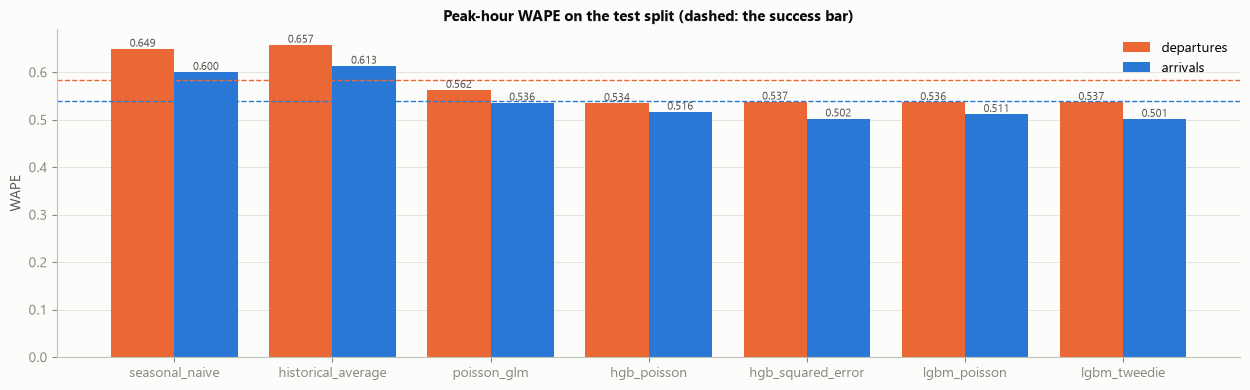

In [8]:
peak = comparison["peak_wape"].unstack("target").loc[list(MODELS), list(TARGETS)]
plots.plot_grouped_bars(
    peak, "Peak-hour WAPE on the test split (dashed: the success bar)", "WAPE", bar
);

**Result → action.**
- **All five candidates beat the peak-hour bar for both targets.** Gradient boosting reaches a peak WAPE of 0.534-0.537 for departures and 0.501-0.516 for arrivals, against a bar of 0.584 and 0.540. That is 17-18% and 14-17% below the seasonal naive. The Poisson GLM only just clears the bar (0.562 and 0.536).
- **Overall** they are also better than the best overall baseline, the historical average: WAPE 0.627-0.639 against 0.716 for departures.
- **The four boosting models are close.** For departures they are within 0.003 of each other at peak hours, and for arrivals within 0.015. With default parameters none of them clearly wins, so tuning (`2.03`) decides between them.
- **Poisson deviance** is lowest for the Poisson-loss models. `lgbm_tweedie` scores worse on it (1.16 against 0.97) because the metric assumes Poisson variance, while its WAPE is as good as the others'.
- **Cost:** LightGBM fits in about 70 s per target, HGB in 75-105 s and the GLM in 45 s, on 8.6M training rows. Every model is at most 1.4 MB. Neither cost limits the nightly batch of the canvas.

→ The ML models are clearly better than the baselines at peak hours. The choice among the boosting models depends on the fairness check below and on tuning.

## 4. Success criterion and fairness

A candidate succeeds if its peak-hour WAPE is at least 10% lower than the best baseline's and no demand group (quintiles of the mean training demand) has a higher WAPE than under that baseline. `2.01` flagged group 1, the quietest stations, as the one most at risk.

In [9]:
checks = {
    (r.name, r.target): success_criterion(r.report, baseline_reports[r.target])
    for r in results
    if r.name in CANDIDATES
}
pd.DataFrame(
    {
        key: {
            "best baseline": check.baseline,
            "peak WAPE improvement": round(check.peak_wape_improvement, 3),
            "groups worse than the baseline": ", ".join(check.worse_groups) or "none",
            "passed": check.passed,
        }
        for key, check in checks.items()
    }
).T.rename_axis(["model", "target"])

best baseline peak WAPE improvement  \
model             target                                             
poisson_glm       departures  seasonal_naive                 0.134   
                  arrivals    seasonal_naive                 0.107   
hgb_poisson       departures  seasonal_naive                 0.176   
                  arrivals    seasonal_naive                 0.139   
hgb_squared_error departures  seasonal_naive                 0.172   
                  arrivals    seasonal_naive                 0.163   
lgbm_poisson      departures  seasonal_naive                 0.173   
                  arrivals    seasonal_naive                 0.148   
lgbm_tweedie      departures  seasonal_naive                 0.173   
                  arrivals    seasonal_naive                 0.165   

                             groups worse than the baseline passed  
model             target                                            
poisson_glm       departures               group_1, group_2  False  
                  arrivals                 group_1, group_2  False  
hgb_poisson       departures                           none   True  
                  arrivals                          group_1  False  
hgb_squared_error departures                           none   True  
                  arrivals                          group_1  False  
lgbm_poisson      departures                        group_1  False  
                  arrivals                          group_1  False  
lgbm_tweedie      departures                           none   True  
                  arrivals                          group_1  False

In [10]:
reports = pd.concat({(r.name, r.target): r.report for r in results}, names=["model", "target"])
segments = reports["wape"].unstack("segment")[SEGMENTS].swaplevel()
segments.reindex(pd.MultiIndex.from_product([TARGETS, MODELS], names=["target", "model"])).round(3)

segment                        group_1  group_2  group_3  group_4  group_5  \
target     model                                                             
departures seasonal_naive        1.245    1.067    0.884    0.753    0.588   
           historical_average    1.254    1.005    0.780    0.679    0.525   
           poisson_glm           1.633    1.095    0.807    0.658    0.528   
           hgb_poisson           1.222    0.957    0.738    0.613    0.478   
           hgb_squared_error     1.244    0.959    0.741    0.616    0.476   
           lgbm_poisson          1.272    0.973    0.746    0.617    0.481   
           lgbm_tweedie          1.210    0.954    0.736    0.612    0.478   
arrivals   seasonal_naive        1.296    1.048    0.863    0.728    0.562   
           historical_average    1.371    1.002    0.767    0.652    0.503   
           poisson_glm           1.877    1.107    0.798    0.642    0.509   
           hgb_poisson           1.331    0.956    0.725    0.595    0.473   
           hgb_squared_error     1.352    0.958    0.727    0.597    0.458   
           lgbm_poisson          1.401    0.974    0.735    0.601    0.469   
           lgbm_tweedie          1.316    0.953    0.725    0.595    0.460   

segment                        top_50  unseen_stations  
target     model                                        
departures seasonal_naive       0.557            1.220  
           historical_average   0.502            2.735  
           poisson_glm          0.508            1.007  
           hgb_poisson          0.454            1.043  
           hgb_squared_error    0.452            1.267  
           lgbm_poisson         0.457            1.191  
           lgbm_tweedie         0.455            1.000  
arrivals   seasonal_naive       0.533            1.232  
           historical_average   0.486            2.954  
           poisson_glm          0.492            1.008  
           hgb_poisson          0.457            1.075  
           hgb_squared_error    0.437            1.325  
           lgbm_poisson         0.451            1.286  
           lgbm_tweedie         0.441            1.001

**Result → action.**
- **Departures:** `hgb_poisson`, `hgb_squared_error` and `lgbm_tweedie` pass the success criterion. `lgbm_poisson` fails it in group 1 (1.272 against 1.245 for the seasonal naive), and the GLM fails it in groups 1 and 2.
- **Arrivals:** no candidate passes. Each one is better than the seasonal naive in groups 2-5 and in the top 50, but slightly worse in **group 1**, the quietest fifth of the stations. The closest is `lgbm_tweedie`, at 1.316 against 1.296.
- In group 1 most hours have zero or one trip, so a WAPE above 1 is normal for every model. There the seasonal naive's copy of last week is hard to beat, because it predicts exactly 0 in most hours.
- The GLM's group-1 WAPE is far worse (1.63 and 1.88). A linear model of the hour's sin/cos cannot reproduce the two commuter peaks, and it spreads demand over the quiet hours instead.

→ As `2.01` expected, the fairness condition decides the outcome. `2.03` must tune with group 1 in view, not only the peak WAPE. The arrivals gap is small (0.02), so tuning may close it.

## 5. Decision metric: high-imbalance station-days

As in `2.01`: a station-day is high-imbalance when its absolute net flow exceeds half of its capacity. The bar is the baselines' precision and recall of about 0.48-0.54 and 0.45-0.48.

In [11]:
train, test = load_training_data()
del train
gc.collect()
X_test = model_inputs(test)
predictions = {key: r.estimator.predict(X_test) for key, r in fitted.items()}
pd.DataFrame(
    {
        name: imbalance_scores(test, predictions[name, "departures"], predictions[name, "arrivals"])
        for name in MODELS
    }
).T.round(3)

,imbalance_days,flagged_days,imbalance_precision,imbalance_recall
seasonal_naive,23294.0,23449.0,0.479,0.482
historical_average,23294.0,19295.0,0.544,0.451
poisson_glm,23294.0,14766.0,0.660,0.418
hgb_poisson,23294.0,14748.0,0.674,0.427
hgb_squared_error,23294.0,14730.0,0.676,0.428
lgbm_poisson,23294.0,13273.0,0.704,0.401
lgbm_tweedie,23294.0,14051.0,0.689,0.416


**Result → action.**
- Every candidate raises **precision**, from 0.48-0.54 to 0.66-0.70: a station-day it flags is more often a real high-imbalance day.
- **Recall** drops, from 0.45-0.48 to 0.40-0.43. The candidates flag only 13-15k days, while the test split has 23k. Count models forecast the expected demand, which smooths out the extreme days in the same way the historical average does.
- `2.01` set the bar as raising both, so the candidates meet it only for precision.

→ The forecasts are better, but to flag imbalance the decision layer will need a lower threshold than the canvas's "half of the capacity", or the upper quantiles of the forecast instead of its mean. The 12-fold backtest (`2.04`) must report both precision and recall per month.

## 6. Unseen stations and stations without a profile

`2.01` expected the profile scores to help the stations without training history. They cannot: the profiles are fitted before 2025-10, so every station opened later has no scores, only the "no profile" flag. Those stations depend on their lags (from their second week), their location and their capacity. The table splits the test hours by whether the station has a profile; the chart shows the busiest station opened since May 2026 in its first two weeks.

In [12]:
no_profile = test["pc1"].isna().to_numpy()
print(
    f"{no_profile.mean():.1%} of the test hours, at {test.loc[no_profile, STATION].nunique()} "
    "stations, have no profile"
)
pd.DataFrame(
    {
        name: {
            f"{target}, {label}": count_metrics(
                test.loc[rows, target], predictions[name, target][rows]
            )["wape"]
            for target in TARGETS
            for label, rows in {"with profile": ~no_profile, "without profile": no_profile}.items()
        }
        for name in MODELS
    }
).T.round(3)

9.7% of the test hours, at 115 stations, have no profile


,"departures, with profile","departures, without profile","arrivals, with profile","arrivals, without profile"
seasonal_naive,0.739,1.220,0.710,1.232
historical_average,0.669,2.735,0.646,2.954
poisson_glm,0.692,1.018,0.675,1.020
hgb_poisson,0.619,1.044,0.606,1.075
hgb_squared_error,0.619,1.309,0.599,1.362
lgbm_poisson,0.626,1.205,0.611,1.301
lgbm_tweedie,0.618,1.000,0.599,1.001


In training, the only stations without a profile are the quiet ones (fewer than 500 trips), so the flag can learn "no profile means little demand". In the test period most stations without a profile are new and busy. To see what the flag does, `lgbm_tweedie` is fitted again for departures with the flag dropped, so a station without a profile only gets the average profile (0).

In [13]:
train, _ = load_training_data()
without_flag = (
    MODELS["lgbm_tweedie"]
    .build("departures")
    .set_params(preprocess__no_profile="drop")
    .fit(model_inputs(train), train["departures"])
)
del train
gc.collect()
flag_check = {
    "with flag": predictions["lgbm_tweedie", "departures"],
    "without flag": without_flag.predict(X_test),
}
actual = test.loc[no_profile, "departures"]
pd.DataFrame(
    {
        label: {
            "WAPE, all stations": count_metrics(test["departures"], y_pred)["wape"],
            "WAPE without profile": count_metrics(actual, y_pred[no_profile])["wape"],
            "mean forecast without profile": y_pred[no_profile].mean(),
            "mean actual without profile": actual.mean(),
        }
        for label, y_pred in flag_check.items()
    }
).T.round(3)

,"WAPE, all stations",WAPE without profile,mean forecast without profile,mean actual without profile
with flag,0.627,1.000,0.003,0.284
without flag,0.634,1.344,0.453,0.284


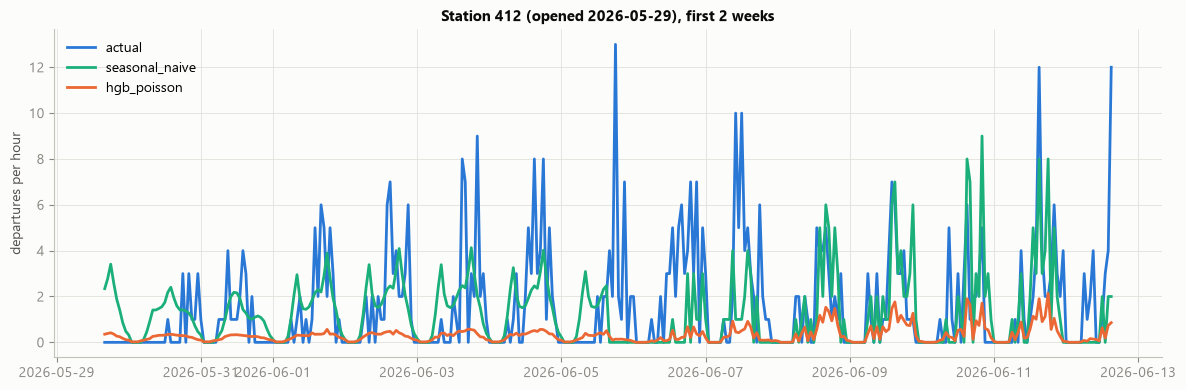

In [14]:
best = comparison.xs("departures")["peak_wape"].drop(list(BASELINES)).idxmin()
opened = test.groupby(STATION)[TIME].min()
new = opened[opened >= NEW_SINCE].index
newest = test[test[STATION].isin(new)].groupby(STATION)["departures"].sum().idxmax()
rows = (
    (test[STATION] == newest)
    & (test[TIME] < opened[newest] + pd.Timedelta(weeks=NEW_STATION_WEEKS))
).to_numpy()
forecasts = pd.DataFrame(
    {
        "actual": test.loc[rows, "departures"].to_numpy(),
        "seasonal_naive": predictions["seasonal_naive", "departures"][rows],
        best: predictions[best, "departures"][rows],
    },
    index=test.loc[rows, TIME],
)
plots.plot_lines(
    forecasts,
    f"Station {newest} (opened {opened[newest]:%Y-%m-%d}), first {NEW_STATION_WEEKS} weeks",
    "departures per hour",
);

**Result → action.**
- **Stations with a profile** (90% of the test hours): boosting reaches a WAPE of about 0.60-0.63, against 0.71-0.74 for the seasonal naive.
- **The 115 stations without a profile** (9.7% of the test hours) are the weak spot. They are almost all the stations opened in 2026.
- **The flag learned "quiet station":** `lgbm_tweedie` forecasts 0.003 departures per hour there, against an actual mean of 0.28, and its WAPE of 1.000 is what a forecast of zero gives. The GLM does the same: the flag is its largest coefficient (section 7).
- **Dropping the flag is no better:** the forecast becomes too high (0.45), and the WAPE rises to 1.34 there and to 0.634 overall.
- The chart shows the gap. At station 412, `hgb_poisson` follows the daily shape but forecasts about 0.3-2 departures in hours with up to 13. The seasonal naive follows the station's own level from its second week on.

→ The 2.01 claim is corrected: the profile scores do not help the stations opened after 2025-10, because those stations have none. The fix is what `1.05` proposed: give a new station profile scores from its first four weeks (only from its fifth week on, so that no hour sees its own demand). That needs time-dependent profiles, and is proposed as a follow-up to this issue. Until then, the backtest (`2.04`) must report the unseen stations as their own segment.

## 7. What the count loss adds

`hgb_poisson` and `hgb_squared_error` are the same model with a different loss. Squared error fits the mean of the counts directly, so it can forecast negative demand in quiet hours, which the clipping at 0 hides. The Poisson loss models the log of the mean, so its forecasts are positive by construction.

In [15]:
loss_rows = ["overall_wape", "peak_wape", "overall_poisson_deviance"]
contrast = pd.concat(
    {
        target: comparison.loc[target].loc[["hgb_poisson", "hgb_squared_error"], loss_rows].T
        for target in TARGETS
    }
)
for target in TARGETS:
    for name in ("hgb_poisson", "hgb_squared_error"):
        contrast.loc[(target, "group_1_wape"), name] = fitted[name, target].report.loc[
            "group_1", "wape"
        ]
    model = fitted["hgb_squared_error", target].estimator
    raw = model[-1].regressor_.predict(model[0].transform(X_test))
    print(f"{target}: {(raw < 0).mean():.1%} of the squared-error forecasts are clipped at 0")
contrast.round(3)

departures: 4.9% of the squared-error forecasts are clipped at 0


arrivals: 3.8% of the squared-error forecasts are clipped at 0


model                                hgb_poisson  hgb_squared_error
departures overall_wape                    0.629              0.635
           peak_wape                       0.534              0.537
           overall_poisson_deviance        0.972              0.984
arrivals   overall_wape                    0.616              0.616
           peak_wape                       0.516              0.502
           overall_poisson_deviance        0.942              0.945
departures group_1_wape                    1.222              1.244
arrivals   group_1_wape                    1.331              1.352

In [16]:
glm = fitted["poisson_glm", "departures"].estimator
coefficients = pd.Series(glm[-1].coef_, index=glm[0].get_feature_names_out())
coefficients.sort_values(key=abs, ascending=False).head(10).round(3).to_frame(
    "log-rate change per standard deviation"
)

,log-rate change per standard deviation
no_profile__missingindicator_pc1,-3.477
demand__departures_same_hour_4w,0.719
cyclical__hour_cos,-0.236
weekday__weekday_6,-0.176
weekday__weekday_5,-0.133
demand__departures_lag_2d,0.133
cyclical__hour_sin,-0.110
demand__arrivals_same_hour_4w,0.094
weekday__weekday_4,-0.077
weekday__weekday_3,-0.074


**Result → action.**
- **What squared error costs:** it forecasts negative demand in 4.9% of the departure hours and 3.8% of the arrival hours, which the clipping hides. With the count loss, forecasts are positive by construction.
- **The difference is small in WAPE:** 0.629 against 0.635 overall for departures, and squared error is even better at arrival peaks (0.502 against 0.516). WAPE scores absolute errors and is dominated by the busy hours, where both losses fit the mean well.
- **The count loss wins where demand is low:** Poisson deviance is 0.972 against 0.984, and group-1 WAPE is 1.222 against 1.244 for departures and 1.331 against 1.352 for arrivals. Group 1 is exactly where the fairness check fails.
- **GLM coefficients:** after the no-profile flag, the largest effects are the 4-week same-hour mean, the hour of the day and the weekend. The model mostly scales a station's recent level by a smooth daily curve, which explains its weakness at the quiet stations.

→ The count loss stays: it is valid for counts, and it is better exactly where the success criterion is at risk. `hgb_squared_error` does not advance; it has done its job as a contrast.

## 8. The logged models reproduce the forecasts

Later stages (Model Registry, batch predictions) load the model artifact of each run, so it must give the same forecasts as the estimator trained here. The artifacts use the skops format, which loads only the listed trusted types.

In [17]:
sample = X_test.sample(10_000, random_state=SEED)
for r in results:
    logged_model = mlflow.sklearn.load_model(f"runs:/{r.run_id}/{MODEL_ARTIFACT}")
    assert np.allclose(logged_model.predict(sample), r.estimator.predict(sample))
print(f"{len(results)} logged models reproduce the forecasts on {len(sample):,} test hours")

14 logged models reproduce the forecasts on 10,000 test hours


## 9. The model families left out

- **Per-station time-series models (ARIMA, Prophet):** about 486 stations × 2 targets would mean some 970 separate models. None of them learns from the other stations, so a station opened in 2026 would have only a few weeks of history to fit. They also need their own retraining and monitoring for each series. The canvas keeps a dedicated time-series model as an optional later comparison for the top stations only.
- **Deep sequence models (LSTM, temporal CNNs):** they need far more tuning and compute than gradient boosting on this table. The current features already give boosting the information they would add: lags, rolling means and calendar.
- **XGBoost:** it offers the same Poisson and Tweedie objectives as LightGBM. Adding it would mean one more dependency for a model of the same family.

## Findings and next steps

**Output**
- 14 MLflow runs in the `mibici` experiment (`train-<model>-<target>`): five candidates and the two baselines for both targets, at one commit and on the same data digests.
  - Each run has the regressor's params, the profiles' fit end, the segment metrics, `fit_seconds` and `model_size_mb`, and the tags `model_family` (`baseline`, `glm`, `boosting`), `target` and `git_commit`.
  - Each run logs the fitted pipeline, preprocessing included, in the skops format.
- `python -m team2_mlops2026.modeling.train` reproduces them in about 25 minutes.

**Comparison with default parameters (test split 2025-10 to 2026-09)**

| Model | Peak WAPE departures | Peak WAPE arrivals | Success departures | Success arrivals | Fit (s) |
|---|---|---|---|---|---|
| seasonal naive (best baseline) | 0.649 | 0.600 | bar: 0.584 | bar: 0.540 | 1 |
| `poisson_glm` | 0.562 | 0.536 | no (groups 1, 2) | no (groups 1, 2) | 44 |
| `hgb_poisson` | **0.534** | 0.516 | **yes** | no (group 1) | 105 |
| `hgb_squared_error` | 0.537 | 0.502 | yes | no (group 1) | 76 |
| `lgbm_poisson` | 0.536 | 0.511 | no (group 1) | no (group 1) | 72 |
| `lgbm_tweedie` | 0.537 | **0.501** | **yes** | no (group 1, closest) | 70 |

**Candidates that advance to tuning (`2.03`)**
- **`lgbm_tweedie`:** it has the best arrivals peak WAPE, the lowest group-1 WAPE of the candidates for both targets, and it passes for departures. It is also the fastest to fit, which matters for a tuning search.
- **`hgb_poisson`:** it has the best departures peak WAPE, passes for departures, and uses scikit-learn only. It is the Poisson-loss counterpart to the Tweedie model.
- **Left out:**
  - `lgbm_poisson`: slightly worse than `lgbm_tweedie` everywhere, and it fails the departures fairness check
  - `hgb_squared_error`: the contrast; it needs clipping and is worse in the quiet groups
  - `poisson_glm`: it fails in two groups for both targets; it remains the interpretable reference

**Implications for the next stages**
- *Tuning (`2.03`):* select on the peak WAPE **and** the group-1 WAPE, since group 1 is where arrivals fail. Validate on later hours of the training split, and only then turn on early stopping.
- *New stations:* the no-profile flag makes the models forecast almost no demand at stations opened after the profile fit. Time-dependent profile scores, available from a station's fifth week, are proposed as a follow-up issue.
- *Backtest (`2.04`):* report the unseen stations and the decision metric's recall per fold. The candidates raise precision but lower recall.